# Polygon fitting: exploration notebook

Points are `(i, j)` pixel coordinates: row `i` counted downward from the top, column `j` rightward (matrix style, origin at the upper left). Edge `e` joins vertex `e` to vertex `(e + 1) % n`.

The notebook has two parts:
1. **Build**: create the point sets and attempt the fits. Nothing is plotted. Each point set records its own completed fit attempts. A point set that can't be built is skipped; a failed fit stops the work on that point set; the rest carry on.
2. **Plot**: draw the results from Part 1. Re-running a plot never recomputes anything.

`engine="mock"` is a pure-Python placeholder that does **not** optimise anything. `engine="lean"` runs the Lean solver (rebuild it with `lake build` in `lean/` after changing Lean code).

In [20]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt

import polyfit
from polyfit import samples, PointSet, build_point_sets, attempt_fits
from polyfit.plotting import plot_points, plot_fit, plot_attempt, plot_pointset, subplot_grid

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Part 1: Build

## Raw point data
Every set of points used below, by name. `samples.ALL` holds the six built-in samples (see `polyfit/samples.py`).

In [21]:
raw_points = {name: make() for name, make in samples.ALL.items()}

# by-hand sample
my_pts = np.array([
    [2, 2], [2, 3], [2, 4], [2, 5], [2, 6],
    [3, 6], [5, 6], [6, 6],
    [6, 5], [6, 4], [6, 3]
])
raw_points["hand_made"] = my_pts

list(raw_points)

['single_pixel',
 'blob',
 'noisy_segment',
 'triangle_outline',
 'square_missing_edge',
 'hexagon_outline',
 'hand_made']

## Point sets
`build_point_sets` asks Lean's `describe` command for each set's exact centre of mass, `diam(P)^2`, inner and outer radii, and convex hull. A set that can't be built (for example `single_pixel`, which has fewer than 2 points) goes into `failures` instead. `list(point_sets.values())` is the plain list of `PointSet`s.

In [22]:
point_sets, failures = build_point_sets(raw_points)

print("built:", list(point_sets))
for name, err in failures.items():
    print(f"skipped {name}: {err}")

built: ['blob', 'noisy_segment', 'triangle_outline', 'square_missing_edge', 'hexagon_outline', 'hand_made']
skipped single_pixel: need at least 2 distinct points, got 1


## What gets sent to the Lean solver

In [23]:
req = polyfit.make_request(my_pts, n_vertices=4, missing_edges=[3])
req.to_json_dict()

{'points': [[2, 2],
  [2, 3],
  [2, 4],
  [2, 5],
  [2, 6],
  [3, 6],
  [5, 6],
  [6, 6],
  [6, 5],
  [6, 4],
  [6, 3]],
 'n': 4,
 'missing': [3]}

## Fit attempts
Each point set gets a plan: a list of fits to attempt, in order. Every completed fit is recorded (frozen, with its start time and duration) in that point set's `attempts`. The first failed fit on a point set stops the work on that set; it is listed in `stopped`, and the other point sets carry on.

An attempt is never repeated: if a point set already has an attempt with the same characteristics (`n_vertices`, `missing_edges`, `engine`), the fitter doesn't run and the recorded attempt is kept. So re-running this cell is harmless; to start the attempts afresh, re-run the **Point sets** cell.

In [24]:
plans = {name: [dict(n_vertices=2)] for name in point_sets}    # a segment fit for every set
plans["noisy_segment"] += [dict(n_vertices=2, engine="mock")]
plans["triangle_outline"] += [dict(n_vertices=3), dict(n_vertices=3, engine="mock")]
plans["square_missing_edge"] += [dict(n_vertices=4, missing_edges=[], engine="lean")]
plans["square_missing_edge"] += [dict(n_vertices=4, missing_edges=[2], engine="lean")]
plans["square_missing_edge"] += [dict(n_vertices=4, missing_edges=[0,2], engine="lean")]
plans["square_missing_edge"] += [dict(n_vertices=3, missing_edges=[], engine="lean")]
plans["square_missing_edge"] += [dict(n_vertices=4, missing_edges=[2], engine="mock")]
plans["hexagon_outline"] += [dict(n_vertices=6, missing_edges=[0], engine="lean")]
plans["hexagon_outline"] += [dict(n_vertices=6), dict(n_vertices=6, engine="mock")]
plans["blob"] += [dict(n_vertices=3, missing_edges=[1], engine="mock")]

stopped = attempt_fits(point_sets, plans)
print("stopped:", stopped or "none")

stopped: none


In [25]:
# Every recorded attempt
print(f"{'point set':20s} {'n':>2s}  {'missing':8s} {'engine':7s} {'fine fit':15s} {'certified':9s} {'F':>8s} {'time (ms)':>9s}")
for name, ps in point_sets.items():
    for a in ps.attempts:
        f = "-" if a.objective is None else f"{a.objective:.4f}"
        print(f"{name:20s} {a.n_vertices:2d}  {str(list(a.missing_edges)):8s} {a.engine:7s} {a.fine_method:15s} {str(a.certified):9s} {f:>8s} {1000 * a.duration_s:9.0f}")

point set             n  missing  engine  fine fit        certified        F time (ms)
blob                  2  []       lean    local_search    True        0.1336       165
blob                  3  [1]      mock    mock            None        0.1525       107
noisy_segment         2  []       lean    local_search    True        0.0378       184
noisy_segment         2  []       mock    mock            None        0.0475       102
triangle_outline      2  []       lean    local_search    True        0.1861       286
triangle_outline      3  []       lean    local_search    True        0.0366       466
triangle_outline      3  []       mock    mock            None        0.0397       134
square_missing_edge   2  []       lean    local_search    True        0.1819       204
square_missing_edge   4  []       lean    local_search    True        0.0941       500
square_missing_edge   4  [2]      lean    local_search    True        0.0475       385
square_missing_edge   4  [0, 2]   lean    l

## Queries
Scoring a polygon of our choosing with `polyfit.evaluate` is a query, not an attempt, so it is not recorded.

In [26]:
# Score any segment you like, exactly
my_segment = polyfit.evaluate(point_sets["noisy_segment"].points, vertices=[[4, 3], [16, 25]])
my_segment.objective_sq

Fraction(139159929119, 65952649477440)

## Error codes
Error codes come back as `polyfit.FitFailed` exceptions. These two requests fail on purpose: one point only (error 1), and two consecutive missing edges (error 2).

In [27]:
error_demos = {}
for label, pts, n, missing in [("one point", samples.single_pixel(), 1, []),
                               ("consecutive missing", my_pts, 4, [3, 0])]:
    try:
        polyfit.fit(pts, n_vertices=n, missing_edges=missing, engine="lean")
    except polyfit.FitFailed as err:
        error_demos[label] = err

for label, err in error_demos.items():
    print(f"{label}: code {err.code}: {err}")
    print()

one point: code 1: solver error 1: diam(P) = 0: all points coincide
polyfit error 1: all points coincide, so diam(P) = 0

consecutive missing: code 2: solver error 2: two cyclically consecutive edges are both missing
polyfit error 2: two cyclically consecutive edges are both missing



# Part 2: Plot

## The raw point data

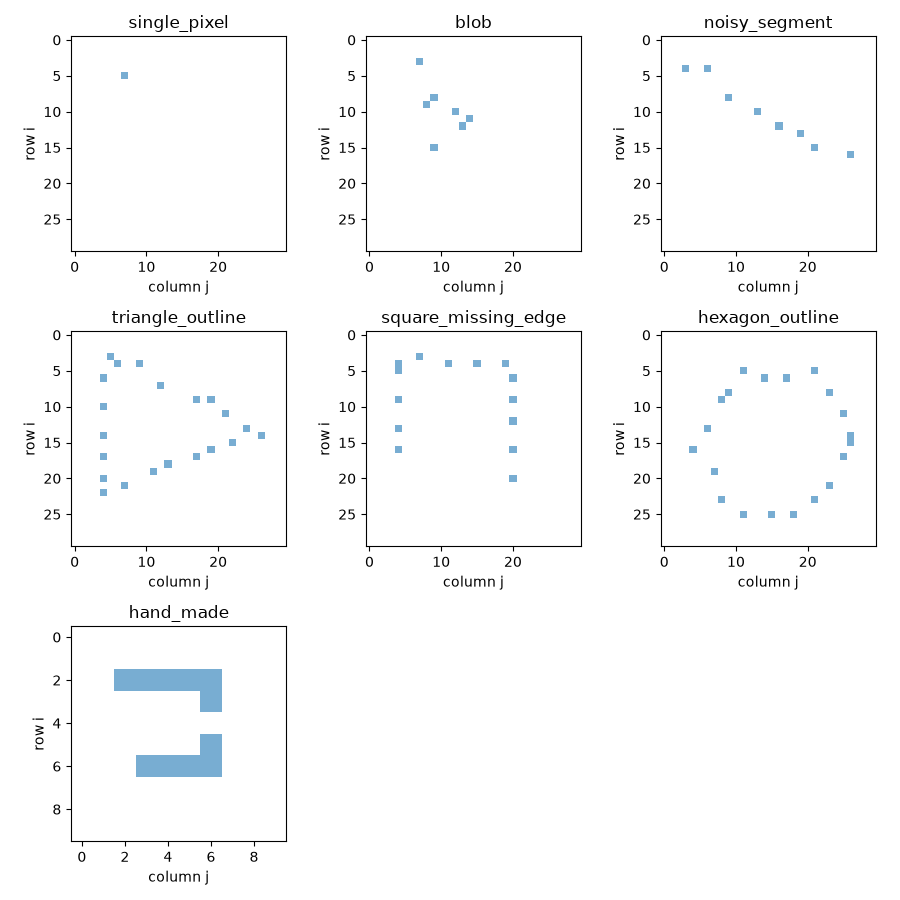

In [28]:
# examples of point distributions from samples.py, plus the hand-made set
names = list(raw_points)
fig, axes = subplot_grid(len(names))
for ax, name in zip(axes, names):
    shape = (10, 10) if name == "hand_made" else (30, 30)
    plot_points(raw_points[name], ax=ax, shape=shape, title=name)
fig.tight_layout()

## Point sets: the fixed data recorded once per set of points
Centre of mass (`+`), inner and outer radii (dotted circles), and the convex hull (green), counterclockwise on screen, starting at the rightmost vertex `h0`.

((Fraction(125, 14), Fraction(86, 7)),
 512,
 Fraction(5085, 196),
 Fraction(35689, 196),
 [[6, 20], [4, 19], [3, 7], [4, 4], [16, 4], [20, 20]])

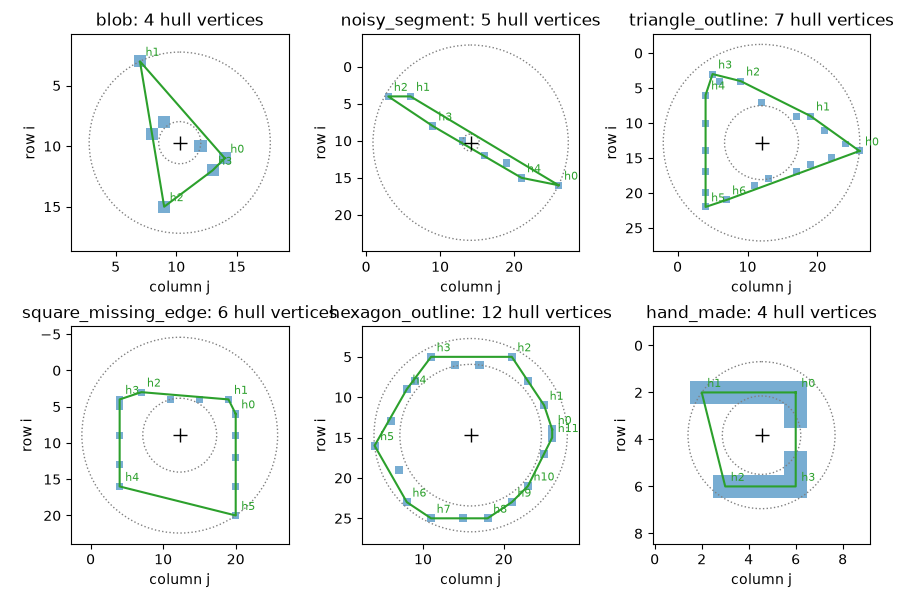

In [29]:
fig, axes = subplot_grid(len(point_sets))
for ax, (name, ps) in zip(axes, point_sets.items()):
    plot_pointset(ps, ax=ax, title=f"{name}: {len(ps.hull)} hull vertices")
fig.tight_layout()

ps = point_sets["square_missing_edge"]
ps.com, ps.diam_sq, ps.inner_radius_sq, ps.outer_radius_sq, ps.hull.tolist()

## Attempts with the placeholder solver

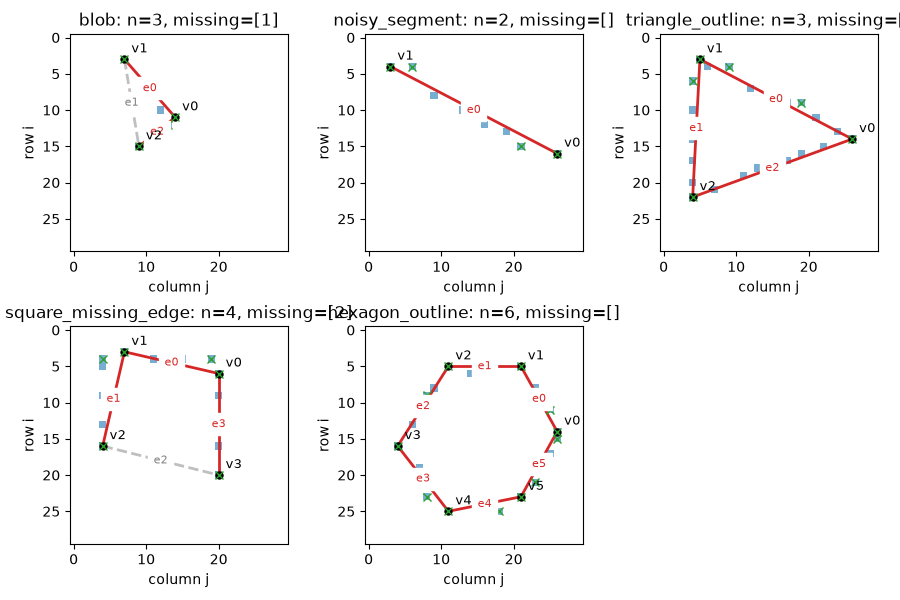

In [30]:
mock_attempts = [(name, ps, a) for name, ps in point_sets.items() for a in ps.attempts if a.engine == "mock"]
fig, axes = subplot_grid(len(mock_attempts))
for ax, (name, ps, a) in zip(axes, mock_attempts):
    plot_attempt(ps, a, ax=ax, shape=(30, 30), title=f"{name}: n={a.n_vertices}, missing={list(a.missing_edges)}")
fig.tight_layout()

## Lean polygon attempts
Each result is the best rough fit (chosen from the reduced hull's vertices, green crosses), refined by the fine and ultra-fine local searches. *Certified* means no polygon in the unit cube around the result (every vertex moved by at most 1 in each coordinate) has a lower `F^2`.

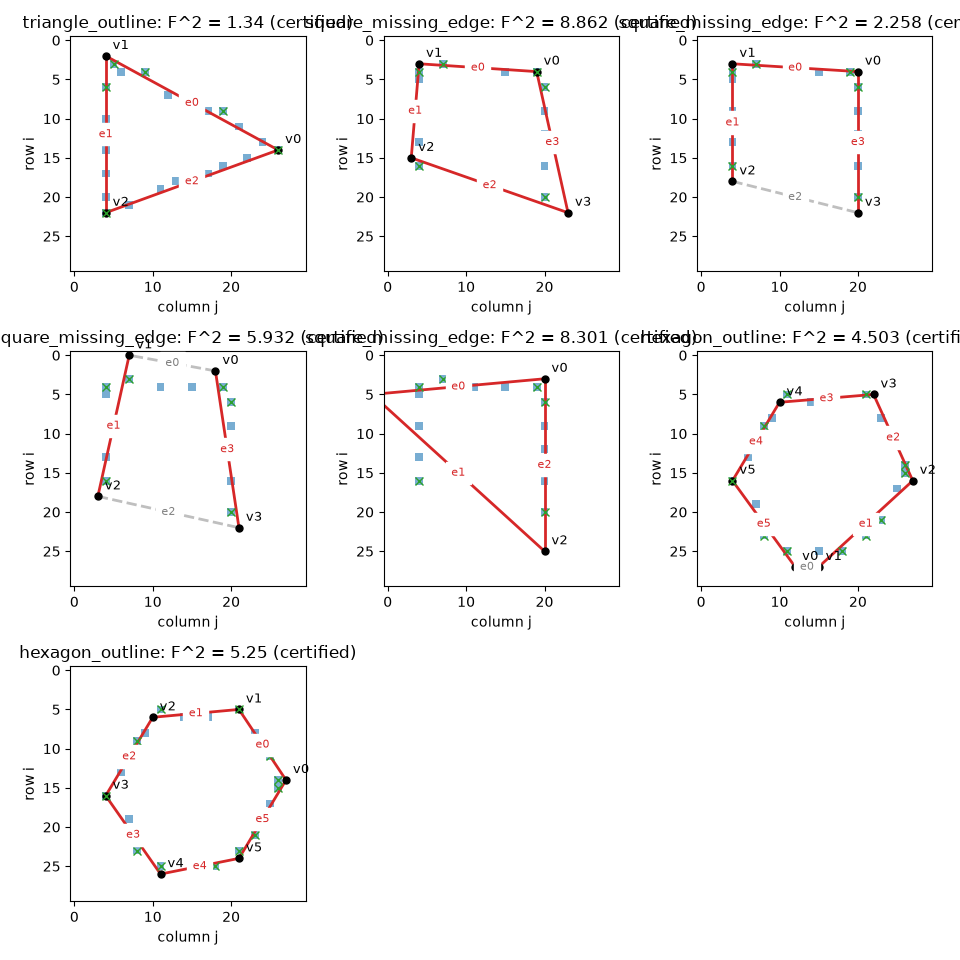

In [31]:
lean_polygons = [(name, ps, a) for name, ps in point_sets.items() for a in ps.attempts
                 if a.engine == "lean" and a.n_vertices >= 3]
fig, axes = subplot_grid(len(lean_polygons), size=3.2)
for ax, (name, ps, a) in zip(axes, lean_polygons):
    plot_attempt(ps, a, ax=ax, shape=(30, 30), title=f"{name}: F^2 = {np.round(1000*float(a.objective_sq),3)}" + (" (certified)" if a.certified else ""))
fig.tight_layout()

## Segment attempts (n = 2) from the Lean solver
The red segment is the fit; `F` is the square root of the exact `F^2` Lean returns. With sparse points the fit overshoots the data by about half the point spacing at each end (see `docs/spec.md`).

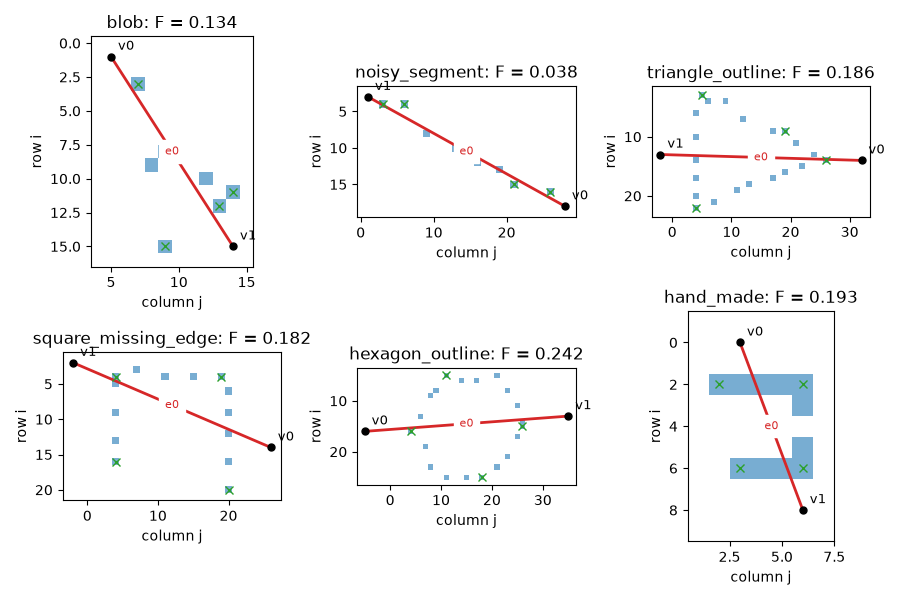

In [32]:
segments = [(name, ps, a) for name, ps in point_sets.items() for a in ps.attempts
            if a.engine == "lean" and a.n_vertices == 2]
fig, axes = subplot_grid(len(segments))
for ax, (name, ps, a) in zip(axes, segments):
    plot_attempt(ps, a, ax=ax, title=f"{name}: F = {a.objective:.3f}")
fig.tight_layout()

# Random points: the best polygon for each n
A random assortment of points on a grid, fitted with a segment, triangle, and so on up to a hexagon. Change `NUM_POINTS`, `GRID` or `SEED` and re-run these cells. A fit that fails (for example, a convex hull with fewer than `n` vertices, error 5) stops the remaining fits for this point set, as for the other point sets.

In [33]:
NUM_POINTS = 20          # how many random points
GRID = (100, 100)        # (rows, columns)
SEED = 1                 # change for a different random assortment

rng = np.random.default_rng(SEED)
random_pts = np.column_stack([rng.integers(0, GRID[0], NUM_POINTS), rng.integers(0, GRID[1], NUM_POINTS)])
random_sets, random_failures = build_point_sets({"random": random_pts})
random_ps = random_sets["random"]
print(f"{len(random_ps.points)} distinct points, {len(random_ps.hull)} hull vertices")

# One plan per fit, run in order. Each plan may also set missing_edges=[...] (n >= 3),
# k=... (how many rough fits to keep, default 2) or engine="mock". Edit, add or delete
# lines freely; a fit that fails stops the remaining fits for this point set.
random_plans = [
    dict(n_vertices=2),
    dict(n_vertices=3),
    dict(n_vertices=4),
    dict(n_vertices=5),
    dict(n_vertices=6),
]
random_stopped = attempt_fits(random_sets, {"random": random_plans})
print("stopped:", random_stopped or "none")

print(f"{'n':>2s} {'F':>8s} {'F^2':>10s} {'certified':9s} {'time (s)':>8s}")
for a in random_ps.attempts:
    print(f"{a.n_vertices:2d} {a.objective:8.4f} {float(a.objective_sq):10.6f} {str(a.certified):9s} {a.duration_s:8.2f}")

20 distinct points, 8 hull vertices
stopped: none
 n        F        F^2 certified time (s)
 2   0.1886   0.035582 True          0.28
 3   0.0932   0.008683 True          1.20
 4   0.0945   0.008926 True          1.31
 5   0.1059   0.011216 True          1.62
 6   0.0724   0.005242 True          3.80


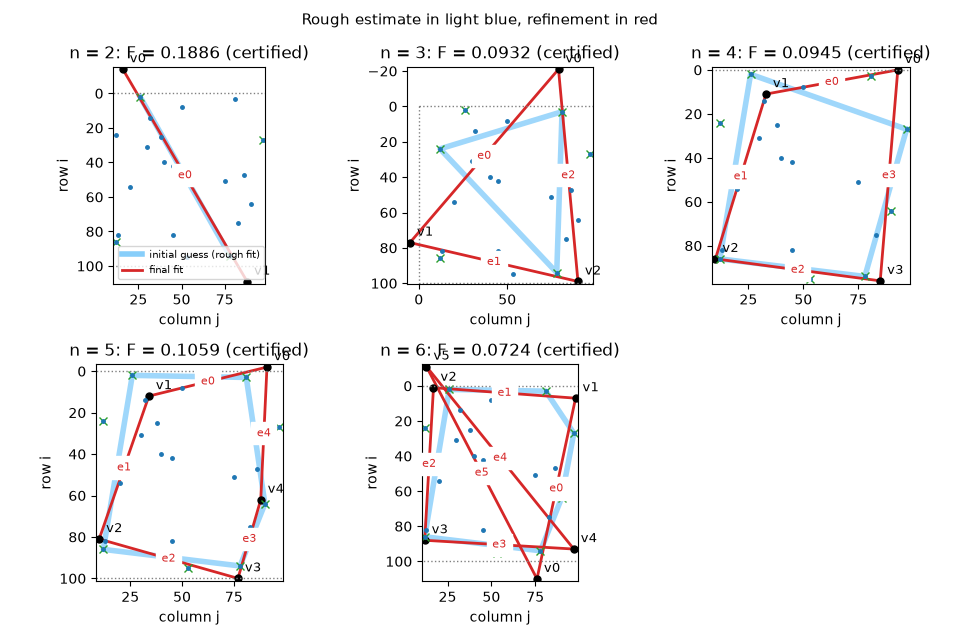

In [34]:
# The initial guess (the best rough fit, light blue, underneath) and the final refined
# polygon (red, on top). The axes fit the whole polygon (vertices may lie outside the
# grid); the dotted box is the grid.
from matplotlib.lines import Line2D

fig, axes = subplot_grid(len(random_ps.attempts), size=3.2)
for ax, a in zip(axes, random_ps.attempts):
    guess = a.rough_fits[0].vertices
    closed = guess if a.n_vertices == 2 else np.vstack([guess, guess[:1]])
    ax.plot(closed[:, 1], closed[:, 0], "-", color="lightskyblue", linewidth=4, alpha=0.8, zorder=0)
    plot_attempt(random_ps, a, ax=ax,
                 title=f"n = {a.n_vertices}: F = {a.objective:.4f}" + (" (certified)" if a.certified else ""))
    ax.plot(random_ps.points[:, 1], random_ps.points[:, 0], ".", color="tab:blue", markersize=5)
    ax.plot([0, GRID[1], GRID[1], 0, 0], [0, 0, GRID[0], GRID[0], 0], ":", color="gray", linewidth=1)
axes[0].legend(handles=[Line2D([], [], color="lightskyblue", linewidth=4, label="initial guess (rough fit)"),
                        Line2D([], [], color="tab:red", linewidth=2, label="final fit")],
               fontsize=7, loc="lower left")
fig.suptitle("Rough estimate in light blue, refinement in red", fontsize=11)
fig.tight_layout()

# Annulus: is convexity violated, and does F decrease with n?
Random points in the ring `R_IN <= r <= R_OUT` around `CENTER`, spread evenly by area (the radius is drawn as `sqrt` of a uniform value between `R_IN^2` and `R_OUT^2`, so the outer part of the ring is not under-sampled). Each fit is checked for **convexity** (every turn in the same direction) and for **crossing edges** (a non-simple polygon). Change the settings and re-run these cells.

In [35]:
NUM_POINTS = 40
CENTER = (50, 50)
R_IN, R_OUT = 35, 50
SEED = 2

rng = np.random.default_rng(SEED)
angle = rng.uniform(0, 2 * np.pi, NUM_POINTS)
radius = np.sqrt(rng.uniform(R_IN ** 2, R_OUT ** 2, NUM_POINTS))
ring_pts = np.round(np.column_stack([CENTER[0] + radius * np.sin(angle),
                                     CENTER[1] + radius * np.cos(angle)])).astype(int)
ring_sets, ring_failures = build_point_sets({"ring": ring_pts})
ring_ps = ring_sets["ring"]
print(f"{len(ring_ps.points)} distinct points, {len(ring_ps.hull)} hull vertices")

# One plan per fit, run in order. Each plan may also set missing_edges=[...] (n >= 3),
# k=... (how many rough fits to keep, default 2) or engine="mock". Edit, add or delete
# lines freely; a fit that fails stops the remaining fits for this point set.
ring_plans = [
    dict(n_vertices=2),
    dict(n_vertices=3),
    dict(n_vertices=4),
    dict(n_vertices=5),
    dict(n_vertices=6),
    dict(n_vertices=6,missing_edges=[0]),
    dict(n_vertices=6,missing_edges=[0,2]),
    dict(n_vertices=6,missing_edges=[0,3]),
    dict(n_vertices=6,missing_edges=[0,2,4]),
    dict(n_vertices=7),
    dict(n_vertices=8),
]
ring_stopped = attempt_fits(ring_sets, {"ring": ring_plans})
print("stopped:", ring_stopped or "none")


def turns(verts):
    """The turn (cross product) at each vertex of the closed polygon; > 0 is counterclockwise on screen."""
    v = np.asarray(verts)
    a, b, c = v, np.roll(v, -1, axis=0), np.roll(v, -2, axis=0)
    return (b[:, 0] - a[:, 0]) * (c[:, 1] - b[:, 1]) - (b[:, 1] - a[:, 1]) * (c[:, 0] - b[:, 0])


def is_convex(verts):
    t = turns(verts)
    return bool(np.all(t >= 0) or np.all(t <= 0))


def has_crossing_edges(verts):
    """Whether two edges that do not share a vertex intersect."""
    v = [tuple(p) for p in np.asarray(verts)]
    n = len(v)
    def orient(p, q, r):
        return np.sign((q[0] - p[0]) * (r[1] - p[1]) - (q[1] - p[1]) * (r[0] - p[0]))
    for e in range(n):
        for f in range(e + 1, n):
            if f == e + 1 or (e == 0 and f == n - 1):
                continue                      # adjacent edges share a vertex
            p1, p2, q1, q2 = v[e], v[(e + 1) % n], v[f], v[(f + 1) % n]
            if orient(p1, p2, q1) * orient(p1, p2, q2) < 0 and orient(q1, q2, p1) * orient(q1, q2, p2) < 0:
                return True
    return False


print(f"{'n':>2s} {'F':>8s} {'convex':>7s} {'crossing':>9s} {'certified':>9s} {'time (s)':>8s}")
for a in ring_ps.attempts:
    convex = "-" if a.n_vertices == 2 else str(is_convex(a.vertices))
    crossing = "-" if a.n_vertices <= 3 else str(has_crossing_edges(a.vertices))
    print(f"{a.n_vertices:2d} {a.objective:8.4f} {convex:>7s} {crossing:>9s} {str(a.certified):>9s} {a.duration_s:8.2f}")
Fs = [a.objective for a in ring_ps.attempts]
print("F decreases with n:", all(f2 < f1 for f1, f2 in zip(Fs, Fs[1:])))

40 distinct points, 14 hull vertices
stopped: none
 n        F  convex  crossing certified time (s)
 2   0.2308       -         -      True     0.37
 3   0.0733    True         -      True     2.51
 4   0.0556    True     False      True     2.88
 5   0.0610    True     False      True     2.55
 6   0.0650    True     False      True     3.53
 6   0.0582   False     False      True     3.69
 6   0.0550    True     False      True     4.33
 6   0.0573   False      True      True     3.99
 6   0.0625    True     False      True     3.37
 7   0.0719    True     False      True     5.79
 8   0.0585    True      True     False     7.72
F decreases with n: False


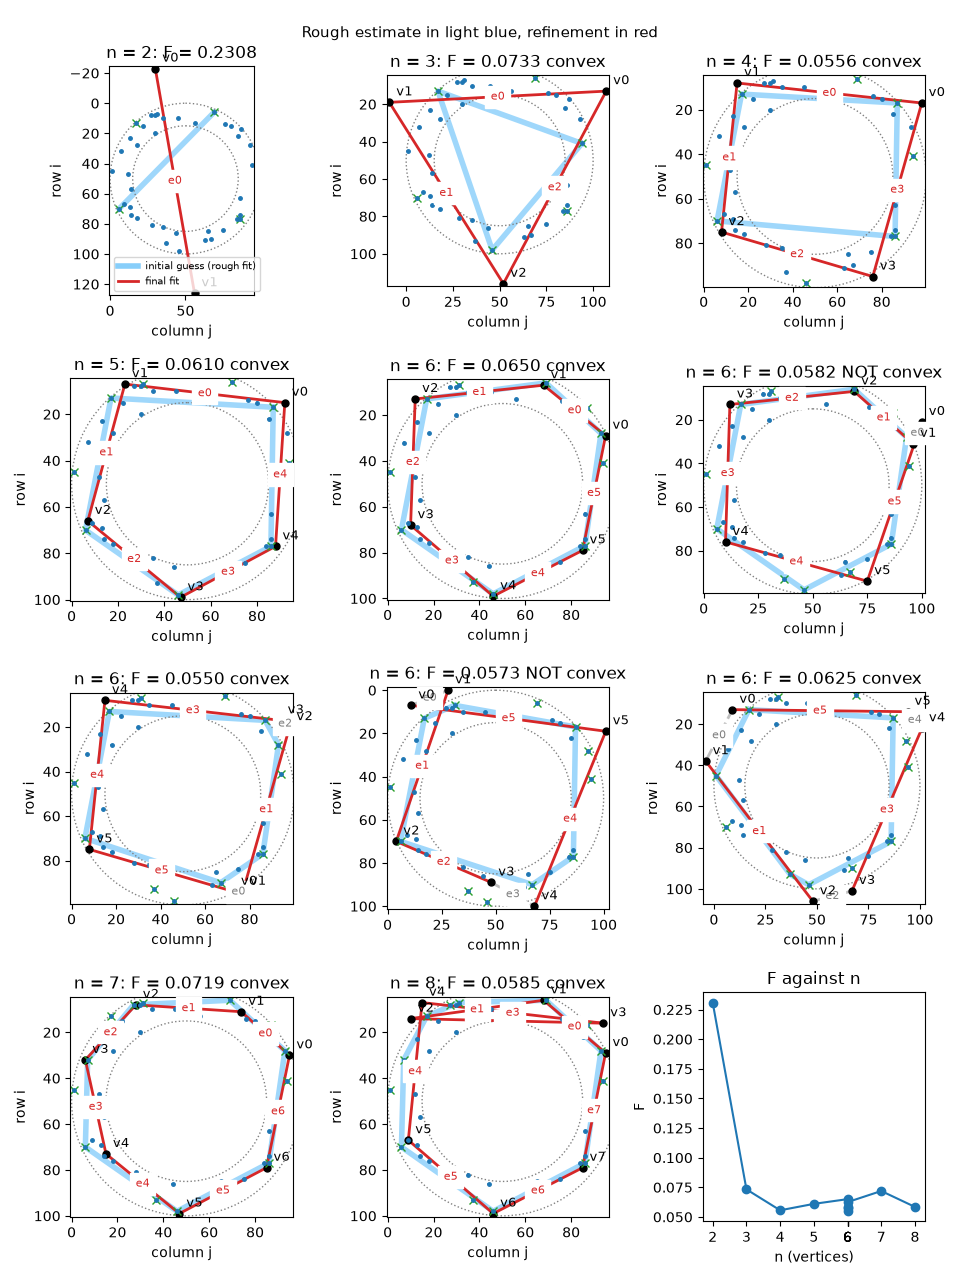

In [36]:
# Initial guess (best rough fit, light blue, underneath) and final fit (red); the dotted
# circles are the ring's edges. Last panel: F against n.
from matplotlib.lines import Line2D
from matplotlib.patches import Circle

fig, axes = subplot_grid(len(ring_ps.attempts) + 1, size=3.2)
for ax, a in zip(axes, ring_ps.attempts):
    guess = a.rough_fits[0].vertices
    closed = guess if a.n_vertices == 2 else np.vstack([guess, guess[:1]])
    ax.plot(closed[:, 1], closed[:, 0], "-", color="lightskyblue", linewidth=4, alpha=0.8, zorder=0)
    shape = "" if a.n_vertices == 2 else (" convex" if is_convex(a.vertices) else " NOT convex")
    plot_attempt(ring_ps, a, ax=ax, title=f"n = {a.n_vertices}: F = {a.objective:.4f}{shape}")
    ax.plot(ring_ps.points[:, 1], ring_ps.points[:, 0], ".", color="tab:blue", markersize=5)
    for r in (R_IN, R_OUT):
        ax.add_patch(Circle((CENTER[1], CENTER[0]), r, fill=False, linestyle=":", color="gray"))
axes[0].legend(handles=[Line2D([], [], color="lightskyblue", linewidth=4, label="initial guess (rough fit)"),
                        Line2D([], [], color="tab:red", linewidth=2, label="final fit")],
               fontsize=7, loc="lower left")

ax = axes[-1]
ax.plot([a.n_vertices for a in ring_ps.attempts], [a.objective for a in ring_ps.attempts], "o-")
ax.set_xlabel("n (vertices)")
ax.set_ylabel("F")
ax.set_title("F against n")
ax.set_xticks([a.n_vertices for a in ring_ps.attempts])
fig.suptitle("Rough estimate in light blue, refinement in red", fontsize=11)
fig.tight_layout()

# Thick data: many more points than edges
A true regular `TRUE_N`-gon drawn as a dense outline (every pixel along it), made "thick" by random noise of size `NOISE` pixels. Here the points far outnumber the edges. The table splits `F^2` into its two parts, `D1 part = Â½ D1(P, Q)^2` (points to polygon) and `D2 part = F^2 - D1 part` (polygon to points), to show which one drives the fit as `n` changes, and whether `F` picks the true `n`. Larger `RADIUS` means more points, and slower fits (roughly with the square of the number of points); with the defaults (about 220 points) the build cell takes about 2 minutes.

In [37]:
TRUE_N = 5               # the true polygon's number of vertices
RADIUS = 25              # its circumradius, in pixels (more radius = more points)
CENTER = (50, 50)
NOISE = 1.0              # standard deviation of the noise added to each point, in pixels
SEED = 1

angles = np.pi / 2 + 2 * np.pi * np.arange(TRUE_N) / TRUE_N
true_verts = np.column_stack([CENTER[0] - RADIUS * np.sin(angles), CENTER[1] + RADIUS * np.cos(angles)])
thick_pts = samples.rasterize_outline(true_verts, noise=NOISE, seed=SEED)
thick_sets, thick_failures = build_point_sets({"thick": thick_pts})
thick_ps = thick_sets["thick"]
print(f"{len(thick_ps.points)} distinct points, {len(thick_ps.hull)} hull vertices")

# One plan per fit, run in order (see the random-points cell for the options).
thick_plans = [
    dict(n_vertices=3),
    dict(n_vertices=4),
    dict(n_vertices=5),
    dict(n_vertices=6),
    dict(n_vertices=7),
    dict(n_vertices=8),
]
thick_stopped = attempt_fits(thick_sets, {"thick": thick_plans})
print("stopped:", thick_stopped or "none")


def d1_part(ps, a):
    """Â½ D1(P, Q)^2 for attempt a, exactly: the points-to-polygon part of F^2."""
    from polyfit import reference
    n, v = a.n_vertices, [tuple(map(int, p)) for p in a.vertices]
    edges = [(v[e], v[(e + 1) % n]) for e in range(n) if e not in a.missing_edges]
    total = sum(min(reference.dist_sq_to_segment(p, q0, q1) for q0, q1 in edges) for p in ps.points)
    return total / (len(ps.points) * ps.diam_sq) / 2


thick_parts = {a.n_vertices: (float(a.objective_sq), float(d1_part(thick_ps, a))) for a in thick_ps.attempts}
print(f"{'n':>2s} {'F':>8s} {'F^2':>10s} {'D1 part':>10s} {'D2 part':>10s} {'certified':>9s} {'time (s)':>8s}")
for a in thick_ps.attempts:
    f2, d1 = thick_parts[a.n_vertices]
    print(f"{a.n_vertices:2d} {a.objective:8.4f} {f2:10.6f} {d1:10.6f} {f2 - d1:10.6f} {str(a.certified):>9s} {a.duration_s:8.1f}")
best = min(thick_ps.attempts, key=lambda a: a.objective_sq)
print(f"lowest F at n = {best.n_vertices} (true n = {TRUE_N})")

223 distinct points, 13 hull vertices
stopped: none
 n        F        F^2    D1 part    D2 part certified time (s)
 3   0.0723   0.005221   0.002897   0.002325      True     12.8
 4   0.0440   0.001937   0.001168   0.000769      True     17.4
 5   0.0215   0.000460   0.000220   0.000241      True     17.5
 6   0.0250   0.000623   0.000231   0.000391      True     26.6
 7   0.0301   0.000907   0.000264   0.000643      True     30.1
 8   0.0316   0.000999   0.000262   0.000737     False     35.9
lowest F at n = 5 (true n = 5)


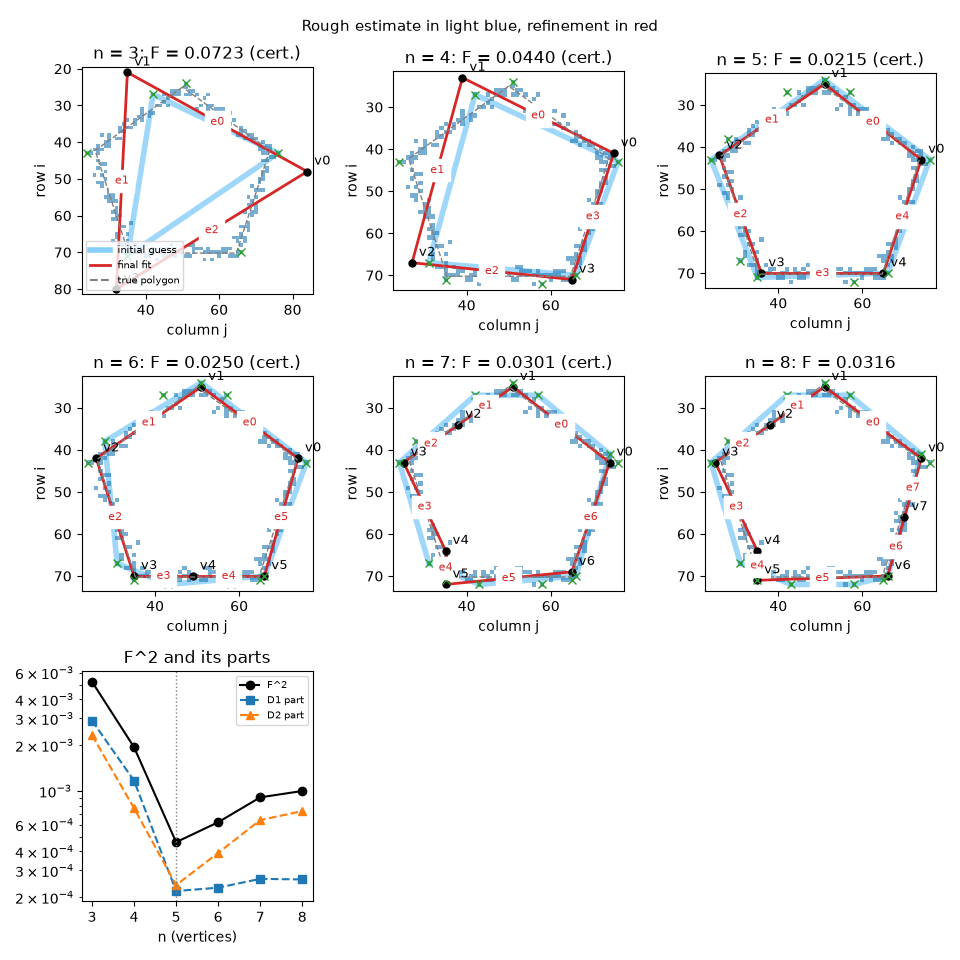

In [38]:
# Initial guess (best rough fit, light blue, underneath) and final fit (red); the dashed
# polygon is the true one. Last panel: F^2 and its two parts against n.
from matplotlib.lines import Line2D

fig, axes = subplot_grid(len(thick_ps.attempts) + 1, size=3.2)
for ax, a in zip(axes, thick_ps.attempts):
    guess = a.rough_fits[0].vertices
    closed = np.vstack([guess, guess[:1]])
    ax.plot(closed[:, 1], closed[:, 0], "-", color="lightskyblue", linewidth=4, alpha=0.8, zorder=0)
    plot_attempt(thick_ps, a, ax=ax, title=f"n = {a.n_vertices}: F = {a.objective:.4f}" + (" (cert.)" if a.certified else ""))
    tv = np.vstack([true_verts, true_verts[:1]])
    ax.plot(tv[:, 1], tv[:, 0], "--", color="gray", linewidth=1)
axes[0].legend(handles=[Line2D([], [], color="lightskyblue", linewidth=4, label="initial guess"),
                        Line2D([], [], color="tab:red", linewidth=2, label="final fit"),
                        Line2D([], [], color="gray", linestyle="--", label="true polygon")],
               fontsize=7, loc="lower left")

ax = axes[-1]
ns = sorted(thick_parts)
ax.plot(ns, [thick_parts[n][0] for n in ns], "o-", color="black", label="F^2")
ax.plot(ns, [thick_parts[n][1] for n in ns], "s--", color="tab:blue", label="D1 part")
ax.plot(ns, [thick_parts[n][0] - thick_parts[n][1] for n in ns], "^--", color="tab:orange", label="D2 part")
ax.axvline(TRUE_N, color="gray", linestyle=":", linewidth=1)
ax.set_yscale("log")
ax.set_xlabel("n (vertices)")
ax.set_xticks(ns)
ax.set_title("F^2 and its parts")
ax.legend(fontsize=7)
fig.suptitle("Rough estimate in light blue, refinement in red", fontsize=11)
fig.tight_layout()